# Nutrition5k: escaneos incrementales y una validación por grupos

No entrena nada ni cambia el código: detecta qué platos son el mismo plato escaneado varias veces y evalúa si una
validación **por grupos** es viable. La partición de `train` no se toca hasta decidirlo.

**Problema.** Nutrition5k escanea un plato, le añade un ingrediente y lo vuelve a escanear (Thames et al., §3.2, p.4).
Cada escaneo es un `dish_id` distinto, y el id es una marca de tiempo Unix. El split oficial mantiene juntos esos
escaneos, pero nuestra validación (10 % de train por hash de `dish_id`) los separa: un plato de validación puede tener
su versión con un ingrediente menos en train.

**Señales para detectarlo**, en dos platos consecutivos en el tiempo (A antes que B):

- Tiempo: segundos entre A y B.
- Ingredientes: todos los ingredientes de A están en B con al menos los mismos gramos. Con eso, la relación es:
  - `adds`: B tiene además ingredientes nuevos (escaneo incremental típico);
  - `more grams`: mismos ingredientes, alguno con más gramos;
  - `identical`: mismos ingredientes y gramos (¿el mismo plato escaneado otra vez?);
  - `unrelated`: ninguna de las anteriores.

In [18]:
import csv
import hashlib
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nutrition5k import load_dataset
from nutrition5k.dataset import PILOT_SEED, split_validation

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

ROOT = Path("data/nutrition5k")
MODE = "complete"
TARGETS = ("mass", "calories", "fat", "carb", "protein")
MAX_GAP = 300           # s; dos escaneos del mismo plato están a menos de esto (ver la tabla de calibración)
GRAMS_TOLERANCE = 1.0   # g; la báscula puede variar un gramo entre escaneos
VALIDATION_FRACTION = 0.1
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
INK, MUTED = "#0b0b0b", "#52514e"

In [19]:
def load_dishes(root):
    """One row per dish of both metadata files, with its ingredients as {ingredient id: grams}."""
    rows = []
    for cafe in ("cafe1", "cafe2"):
        with open(root / f"metadata/dish_metadata_{cafe}.csv", newline="") as handle:
            for row in csv.reader(handle):
                calories, mass, fat, carb, protein = map(float, row[1:6])
                rows.append({
                    "dish_id": row[0], "mass": mass, "calories": calories, "fat": fat, "carb": carb, "protein": protein,
                    "ingredients": {row[i]: float(row[i + 2]) for i in range(6, len(row), 7)},
                })
    dishes = pd.DataFrame(rows).set_index("dish_id")
    dishes["time"] = dishes.index.str.removeprefix("dish_").astype(int)
    return dishes.sort_values("time")


dishes = load_dishes(ROOT)
dataset = load_dataset(ROOT, full=True, frame_mode=MODE)
train, validation = split_validation(dataset.train)  # the current validation, as `train` builds it
dishes["official"] = "none"
dishes.loc[[record.dish_id for record in dataset.train], "official"] = "train"
dishes.loc[[record.dish_id for record in dataset.test], "official"] = "test"
dishes["current"] = dishes["official"]
dishes.loc[[record.dish_id for record in validation], "current"] = "val"
FIRST_FRAME = {record.dish_id: record.frame_paths[0] for record in (*dataset.train, *dataset.test) if record.frame_paths}
dishes["current"].value_counts()

current
train    3638
test      709
val       404
none      255
Name: count, dtype: int64

## 1. Relación entre platos consecutivos

Cada plato se compara con el inmediatamente anterior en el tiempo. La tabla da, por tramo de separación, qué
fracción de pares tiene cada relación: sirve para calibrar `MAX_GAP`.

In [20]:
def relation(before, after, tolerance=GRAMS_TOLERANCE):
    """How the later dish relates to the earlier one, from their ingredients."""
    if not before or not all(key in after and after[key] >= grams - tolerance for key, grams in before.items()):
        return "unrelated"
    if before == after:
        return "identical"
    return "adds" if len(after) > len(before) else "more grams"


pairs = pd.DataFrame({
    "before": dishes.index[:-1],
    "after": dishes.index[1:],
    "gap": np.diff(dishes["time"].to_numpy()),
    "relation": [relation(a, b) for a, b in zip(dishes["ingredients"].iloc[:-1], dishes["ingredients"].iloc[1:])],
})
pairs["gap bucket"] = pd.cut(pairs["gap"], [0, 30, 60, 90, 120, 300, 600, 3600, np.inf])
calibration = pd.crosstab(pairs["gap bucket"], pairs["relation"], normalize="index").mul(100).round(1)
calibration["pairs"] = pairs["gap bucket"].value_counts()
calibration

relation,adds,identical,more grams,unrelated,pairs
gap bucket,,,,,
"(0.0, 30.0]",86.1,4.2,1.0,8.7,1107
"(30.0, 60.0]",65.0,8.5,0.4,26.0,2071
"(60.0, 90.0]",27.8,6.4,0.4,65.4,518
"(90.0, 120.0]",12.0,2.6,0.9,84.5,233
"(120.0, 300.0]",7.4,3.3,0.3,89.1,366
"(300.0, 600.0]",2.1,1.0,0.5,96.3,191
"(600.0, 3600.0]",0.7,0.0,1.0,98.3,286
"(3600.0, inf]",0.0,0.0,0.4,99.6,233


## 2. ¿Respeta el split oficial estos enlaces?

Un enlace es un par consecutivo a menos de `MAX_GAP` segundos con relación distinta de `unrelated`. Si el split
oficial agrupa los escaneos incrementales, casi ningún enlace `adds` debería cruzar train/test. Así se valida la
regla con el propio dataset.

Columnas de la tabla, una fila por tipo de relación:

- `links`: número de enlaces de ese tipo, es decir, pares de platos consecutivos (A justo antes que B) a menos de
  `MAX_GAP` segundos cuya relación es esa. Cada enlace dice "B parece el mismo plato físico que A".
- `crossing`: cuántos de esos enlaces tienen un plato en train y el otro en test **del split oficial**. Son platos que
  la regla considera el mismo plato pero que el split oficial separó.
- `crossing_pct`: `crossing / links × 100`.

Cómo leerla: si la regla y el split oficial coinciden en qué es "el mismo plato", `crossing_pct` es casi 0. Un valor
bajo en `adds` confirma que la regla detecta los escaneos incrementales que el split oficial ya agrupa. Un valor alto
indica pares que el split oficial no agrupó: o la regla se equivoca ahí, o el split oficial deja esa fuga en test
(para `identical`, las imágenes de abajo ayudan a decidirlo). Los platos que no están en ningún split oficial
(`cafe2`) no cuentan como cruce.

In [21]:
links = pairs[(pairs["gap"] <= MAX_GAP) & (pairs["relation"] != "unrelated")].copy()
links["official pair"] = dishes.loc[links["before"], "official"].to_numpy() + " → " + dishes.loc[links["after"], "official"].to_numpy()
links["crosses train/test"] = links["official pair"].isin(["train → test", "test → train"])
links.groupby("relation").agg(links=("gap", "size"), crossing=("crosses train/test", "sum"),
                              crossing_pct=("crosses train/test", lambda values: 100 * values.mean())).round(1)

,links,crossing,crossing_pct
relation,,,
adds,2499,2,0.1
identical,275,66,24.0
more grams,25,3,12.0


Los pares `identical` que cruzan train/test pueden ser el mismo plato escaneado dos veces (o dos platos servidos
iguales). Se ven todos aquí, en figuras de 10 pares, y después 4 pares `adds` de referencia: si las imágenes son el mismo plato, test también tiene casi duplicados de train, y eso no se
puede arreglar sin cambiar el test oficial (solo informarlo).

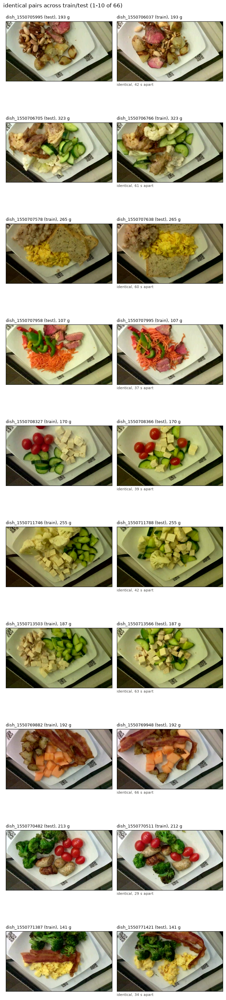

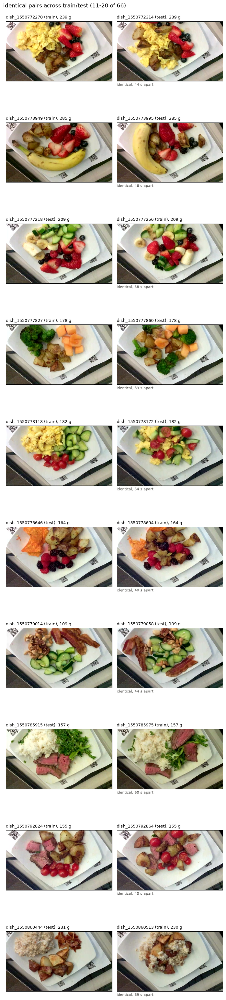

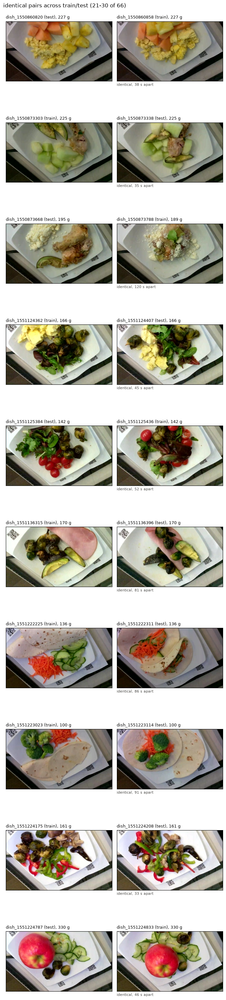

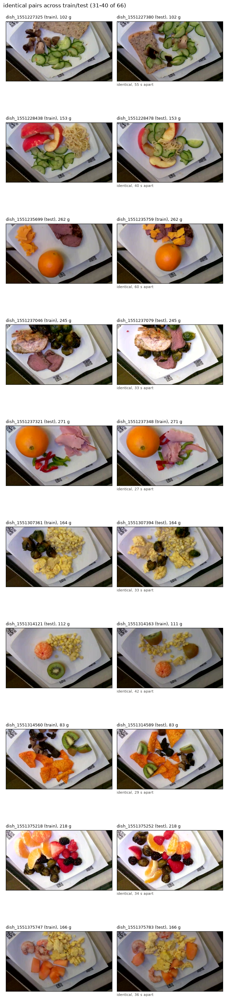

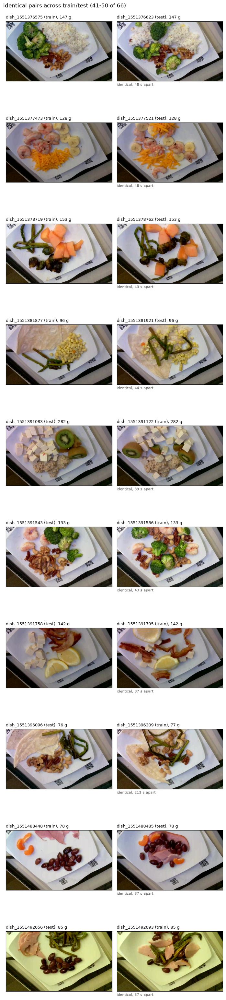

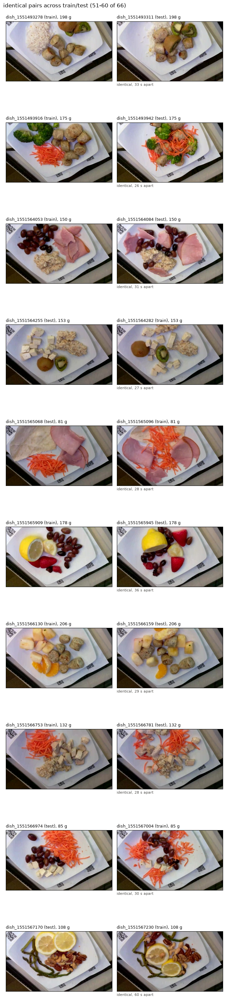

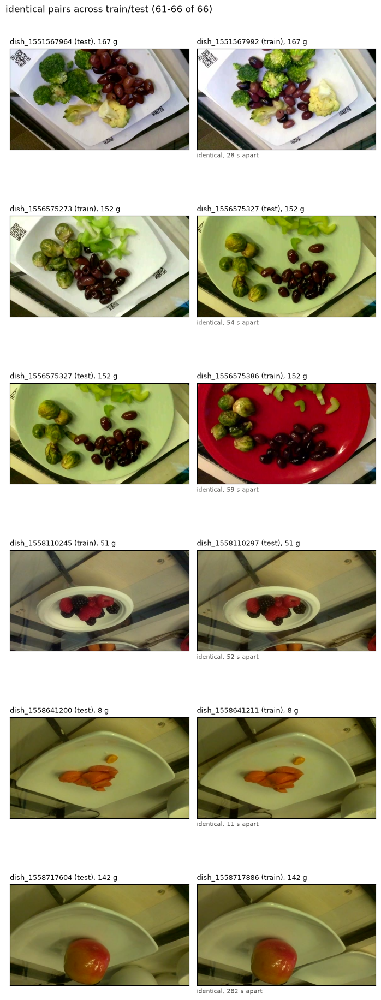

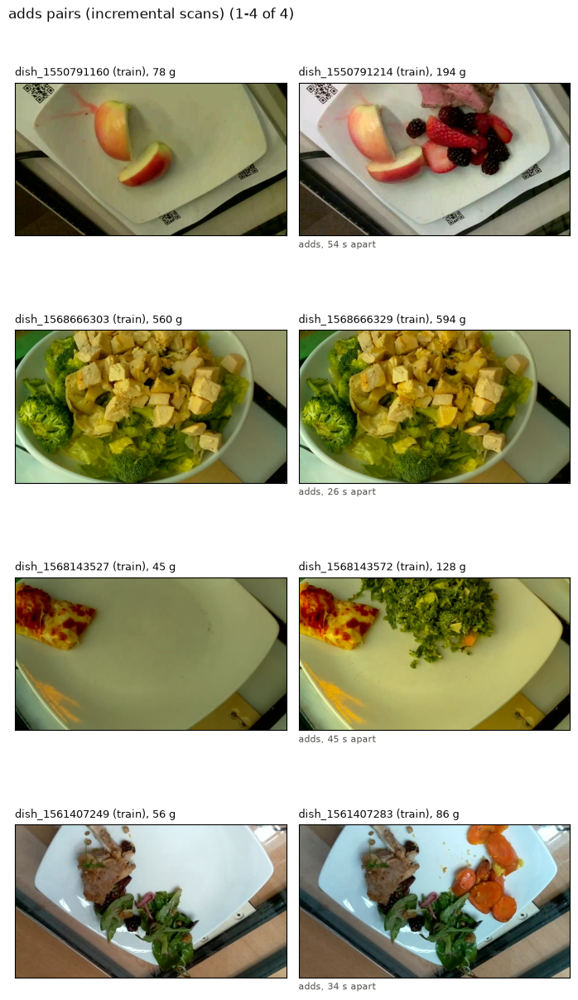

In [ ]:
def show_pairs(pair_rows, title, count=None, per_figure=10):
    """First frame of both dishes of each pair, side by side; every pair unless `count` is given."""
    pair_rows = [row for _, row in pair_rows.iterrows() if row["before"] in FIRST_FRAME and row["after"] in FIRST_FRAME][:count]
    if not pair_rows:
        print("no frames for these dishes in data/")
        return
    # Several figures of `per_figure` pairs, so a long list stays readable.
    for start in range(0, len(pair_rows), per_figure):
        chunk = pair_rows[start:start + per_figure]
        _pair_figure(chunk, f"{title} ({start + 1}-{start + len(chunk)} of {len(pair_rows)})")


def _pair_figure(pair_rows, title):
    fig, axes = plt.subplots(len(pair_rows), 2, figsize=(7, 3.2 * len(pair_rows)), squeeze=False)
    for (left, right), row in zip(axes, pair_rows):
        for ax, dish in ((left, row["before"]), (right, row["after"])):
            ax.imshow(plt.imread(FIRST_FRAME[dish]))
            ax.set_title(f"{dish} ({dishes.loc[dish, 'official']}), {dishes.loc[dish, 'mass']:.0f} g",
                         loc="left", color=INK, fontsize=9)
            ax.set_xticks([]), ax.set_yticks([])
        right.set_xlabel(f"{row['relation']}, {row['gap']} s apart", color=MUTED, fontsize=8, loc="left")
    fig.suptitle(title, x=0.01, ha="left", color=INK)
    plt.tight_layout()
    plt.show()


show_pairs(links[(links["relation"] == "identical") & links["crosses train/test"]], "identical pairs across train/test", count=4)
show_pairs(links[links["relation"] == "adds"], "adds pairs (incremental scans)", count=4)

Podemos ver que los platos identical no son realmente identicos, y tienen los mismos ingredientes pero estan repartidos y posicionados de forma diferentes.

## 3. Grupos

Los enlaces se unen en grupos (un grupo = un plato físico con todos sus escaneos). `INCLUDE_IDENTICAL` decide si los
re-escaneos idénticos también agrupan: para validación conviene que sí, porque un duplicado exacto es la peor fuga.

In [ ]:
INCLUDE_IDENTICAL = False


def build_groups(links, include_identical):
    """Group id (the first dish of its chain) for every dish; chains of linked consecutive dishes."""
    chosen = links if include_identical else links[links["relation"] != "identical"]
    group = pd.Series(dishes.index, index=dishes.index)
    for before, after in zip(chosen["before"], chosen["after"]):  # pairs are in time order, so one pass suffices
        group[after] = group[before]
    return group


dishes["group"] = build_groups(links, INCLUDE_IDENTICAL)
sizes = dishes.groupby("group").size()
print(f"{len(dishes)} dishes → {len(sizes)} groups; {(sizes == 1).sum()} single dishes, "
      f"mean size {sizes.mean():.2f}, largest {sizes.max()}")

fig, ax = plt.subplots(figsize=(7, 3))
counts = sizes.value_counts().sort_index()
ax.bar(counts.index, counts.to_numpy(), color=SERIES[0])
ax.set_xlabel("Dishes per group", color=MUTED)
ax.set_ylabel("Groups", color=MUTED)
ax.set_title("Group sizes", loc="left", color=INK)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Fuga de la validación actual

Para cada plato de validación: ¿hay otro plato de su mismo grupo en train? Se compara con test frente a train
(la referencia de un split bien hecho).

In [ ]:

def leakage(assignment, held_out):
    """Share of `held_out` dishes whose group also has a train dish."""
    groups_in_train = set(dishes.loc[assignment == "train", "group"])
    rows = dishes[assignment == held_out]
    return 100 * rows["group"].isin(groups_in_train).mean()


pd.DataFrame({
    "current val vs train": [leakage(dishes["current"], "val")],
    "official test vs train": [leakage(dishes["current"], "test")],
}, index=["% dishes with a train dish in their group"]).round(1)

## 5. Propuesta: validación por grupos

Igual que la actual (hash determinista con la misma semilla, 10 % de los platos de train), pero se ordenan **grupos**
en vez de platos y se van añadiendo grupos enteros hasta llegar al 10 %. Así ningún grupo queda partido entre train
y validación. Se comprueba: tamaño, fuga, medias de los objetivos y distancia temporal a train (debería parecerse a
la de test).

In [ ]:
def grouped_validation(train_ids, fraction=VALIDATION_FRACTION):
    """Whole groups, in sha256 order of their group id, until `fraction` of the train dishes is held out."""
    groups = dishes.loc[train_ids, "group"]
    order = sorted(groups.unique(), key=lambda group: hashlib.sha256(f"{PILOT_SEED}:validation:{group}".encode()).digest())
    target, held_out = round(len(train_ids) * fraction), []
    members = groups.groupby(groups).groups
    for group in order:
        if len(held_out) >= target:
            break
        held_out.extend(members[group])
    return set(held_out)


official_train = list(dishes.index[dishes["official"] == "train"])
proposed_val = grouped_validation(official_train)
dishes["proposed"] = dishes["official"]
dishes.loc[list(proposed_val), "proposed"] = "val"

train_times = {name: np.sort(dishes.loc[dishes[name] == "train", "time"].to_numpy()) for name in ("current", "proposed")}


def median_gap_to_train(assignment, held_out):
    times, reference = dishes.loc[dishes[assignment] == held_out, "time"].to_numpy(), train_times[assignment]
    position = np.clip(np.searchsorted(reference, times), 1, len(reference) - 1)
    gap = np.minimum(np.abs(times - reference[position - 1]), np.abs(reference[position] - times))
    return np.median(gap), 100 * (gap <= 120).mean()


rows = {}
for name, assignment, held_out in (("current val", "current", "val"), ("proposed val", "proposed", "val"),
                                    ("official test", "current", "test")):
    selected = dishes[dishes[assignment] == held_out]
    median, within = median_gap_to_train(assignment, held_out)
    rows[name] = {"dishes": len(selected), "groups": selected["group"].nunique(),
                  "leakage (%)": leakage(dishes[assignment], held_out),
                  "median s to train": median, "within 120 s of train (%)": within,
                  **selected[list(TARGETS)].mean().add_prefix("mean ").to_dict()}
comparison = pd.DataFrame(rows).T
comparison.round(1)

## 6. Conclusión (se rellena con los números de arriba)

La estrategia es viable si:

1. los enlaces `adds` casi nunca cruzan train/test (la regla reproduce el criterio del split oficial);
2. la validación propuesta tiene fuga 0 y un tamaño parecido al actual;
3. su distancia temporal a train se parece a la de test y las medias de los objetivos no se desvían mucho.

Para aplicarla (no hecho): `split_validation` recibiría el id de grupo de cada plato y apartaría grupos enteros. Eso
cambia la validación, así que los runs ya hechos no serían comparables con los nuevos (habría que repetir la etapa 1
o, como mínimo, reevaluar `best.pt` de cada run sobre la nueva validación, sabiendo que la mejor época se eligió con la
antigua). Los re-escaneos `identical` entre train y test oficiales no se pueden corregir sin cambiar el test oficial:
solo se pueden informar.

In [ ]:
adds = links[links["relation"] == "adds"]
print(f"1. adds links crossing train/test: {adds['crosses train/test'].sum()} of {len(adds)} "
      f"({100 * adds['crosses train/test'].mean():.2f} %)")
print(f"2. proposed validation: {comparison.loc['proposed val', 'dishes']:.0f} dishes "
      f"(current {comparison.loc['current val', 'dishes']:.0f}), leakage {comparison.loc['proposed val', 'leakage (%)']:.1f} % "
      f"(current {comparison.loc['current val', 'leakage (%)']:.1f} %)")
print(f"3. dishes within 120 s of train: proposed val {comparison.loc['proposed val', 'within 120 s of train (%)']:.1f} %, "
      f"official test {comparison.loc['official test', 'within 120 s of train (%)']:.1f} %, "
      f"current val {comparison.loc['current val', 'within 120 s of train (%)']:.1f} %")